# LGD, EAD and Expected Loss

Completes the credit risk model: the PD model (`credit_risk_model.ipynb`) says **how likely** a borrower is to default; this notebook estimates **how much is lost** when they do.

- **LGD** (Loss Given Default) = 1 − recovery rate, modelled in two stages: (1) is anything recovered at all? (2) if so, how much?
- **EAD** (Exposure at Default) = credit conversion factor (CCF) × funded amount
- **Expected Loss** = PD × LGD × EAD, per loan and for the whole portfolio

LGD and EAD are estimated on written-off loans only, because their recoveries are final.

In [1]:
import sys
sys.path.append('../src/')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, mean_absolute_error

from utils import LogisticRegression_with_p_values, LinearRegression
from preprocessing import PD_FEATURES, WRITTEN_OFF_STATUSES, pd_design_matrix
from expected_loss import (LGD_EAD_FEATURES, lgd_ead_design_matrix,
                           recovery_rate, credit_conversion_factor)
sns.set()

## Load the preprocessed 2007-2014 loans (train + test)

In [2]:
needed = set(PD_FEATURES + LGD_EAD_FEATURES + ['loan_status', 'recoveries', 'total_rec_prncp'])
parts = [pd.read_csv(f'../data/processed/loan_data_inputs_{s}.csv', index_col=0,
                     usecols=lambda c: c in needed or c == 'Unnamed: 0', low_memory=False)
         for s in ('train', 'test')]
loan_data = pd.concat(parts)
loan_data.shape

(466285, 137)

In [3]:
# FIX: the stored 'mths_since_issue_d:>84' column used range(85, max), which left out the oldest loans.
loan_data['mths_since_issue_d:>84'] = np.where(loan_data['mths_since_issue_d'] >= 85, 1, 0)

## Targets: recovery rate and credit conversion factor

In [4]:
defaults = loan_data[loan_data['loan_status'].isin(WRITTEN_OFF_STATUSES)].copy()
defaults['recovery_rate'] = recovery_rate(defaults)
defaults['recovery_rate_0_1'] = np.where(defaults['recovery_rate'] == 0, 0, 1)
defaults['CCF'] = credit_conversion_factor(defaults)
print(f'{len(defaults):,} written-off loans')
defaults[['recovery_rate', 'CCF']].describe()

43,236 written-off loans


,recovery_rate,CCF
count,43236.000000,43236.000000
mean,0.060770,0.735952
std,0.089202,0.200742
min,0.000000,0.000438
25%,0.000000,0.632088
50%,0.029466,0.789908
75%,0.114044,0.888543
max,1.000000,1.000000


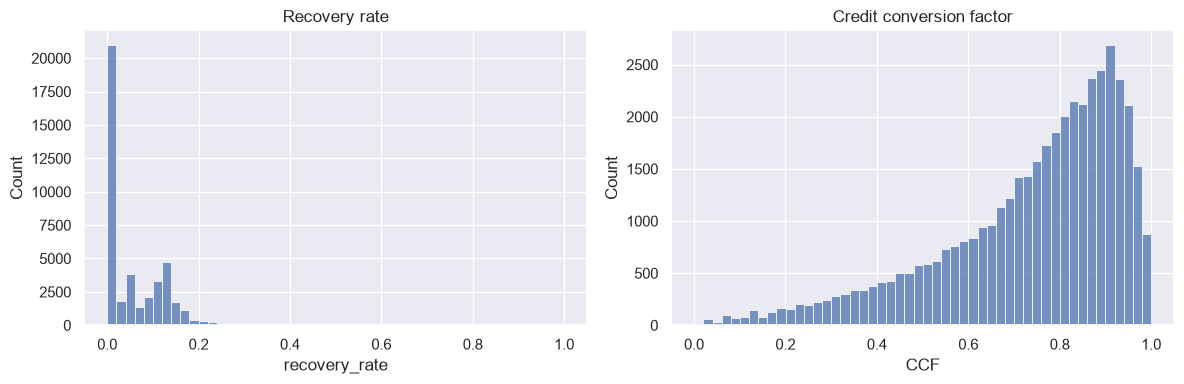

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(defaults['recovery_rate'], bins=50, ax=axes[0]).set_title('Recovery rate')
sns.histplot(defaults['CCF'], bins=50, ax=axes[1]).set_title('Credit conversion factor')
plt.tight_layout()

In [6]:
share_zero = (defaults['recovery_rate_0_1'] == 0).mean()
print(f'{share_zero:.1%} of written-off loans recovered nothing, so LGD is modelled in two stages.')

43.6% of written-off loans recovered nothing, so LGD is modelled in two stages.


## LGD stage 1: is anything recovered? (logistic regression)

In [7]:
X = lgd_ead_design_matrix(defaults)
X_train, X_test, y1_train, y1_test = train_test_split(
    X, defaults['recovery_rate_0_1'], test_size=0.2, random_state=42)

# newton-cholesky converges on unscaled inputs (funded_amnt, annual_inc...) where lbfgs stalls,
# and a very large C makes it effectively unpenalised, so the p-values are valid.
lgd_stage_1 = LogisticRegression_with_p_values(solver='newton-cholesky', C=1e6, max_iter=200)
lgd_stage_1.fit(X_train, y1_train)

summary_stage_1 = pd.DataFrame({'Feature name': ['Intercept'] + list(X.columns),
                                'Coefficients': np.r_[lgd_stage_1.intercept_, lgd_stage_1.coef_[0]],
                                'p_values': np.r_[np.nan, lgd_stage_1.p_values]})
summary_stage_1

,Feature name,Coefficients,p_values
0,Intercept,-4.531849e+00,NaN
1,grade:A,2.088390e+00,5.907602e-125
2,grade:B,1.565344e+00,1.375850e-107
3,grade:C,1.194165e+00,4.459261e-68
4,grade:D,9.033236e-01,1.223316e-36
5,grade:E,5.044781e-01,1.639755e-10
6,grade:F,2.631993e-01,3.874072e-03
7,home_ownership:MORTGAGE,-1.819753e-02,4.892596e-01
8,home_ownership:NONE,1.067899e+00,3.264259e-01
9,home_ownership:OTHER,-1.182482e-01,7.847431e-01


In [8]:
p_recovery_test = lgd_stage_1.model.predict_proba(X_test.to_numpy())[:, 1]
auc_stage_1 = roc_auc_score(y1_test, p_recovery_test)
print(f'Stage 1 AUROC on held-out defaults: {auc_stage_1:.3f}')
pd.crosstab(y1_test, np.where(p_recovery_test > 0.5, 1, 0),
            rownames=['Actual'], colnames=['Predicted'], normalize=True)

Stage 1 AUROC on held-out defaults: 0.690


Predicted,0,1
Actual,,
0,0.220167,0.221554
1,0.119912,0.438367


## LGD stage 2: how much is recovered? (linear regression on loans with recoveries)

In [9]:
recovered = defaults[defaults['recovery_rate_0_1'] == 1]
X2 = lgd_ead_design_matrix(recovered)
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, recovered['recovery_rate'], test_size=0.2, random_state=42)

lgd_stage_2 = LinearRegression()
lgd_stage_2.fit(X2_train, y2_train)

summary_stage_2 = pd.DataFrame({'Feature name': ['Intercept'] + list(X2.columns),
                                'Coefficients': np.r_[lgd_stage_2.intercept_, lgd_stage_2.coef_],
                                'p_values': np.r_[np.nan, lgd_stage_2.p]})
summary_stage_2

,Feature name,Coefficients,p_values
0,Intercept,1.617836e-01,NaN
1,grade:A,-1.327232e-02,5.113638e-03
2,grade:B,-6.726018e-03,7.868887e-02
3,grade:C,-1.061239e-04,9.771940e-01
4,grade:D,3.138131e-03,4.168481e-01
5,grade:E,1.226653e-02,3.876944e-03
6,grade:F,1.800737e-02,1.890426e-04
7,home_ownership:MORTGAGE,2.516923e-03,9.217979e-02
8,home_ownership:NONE,-1.356851e-04,9.976057e-01
9,home_ownership:OTHER,8.633238e-04,9.660710e-01


Stage 2 correlation (actual vs predicted recovery rate): 0.269
Stage 2 MAE: 0.044


Text(0.5, 1.0, 'Stage 2 residuals')

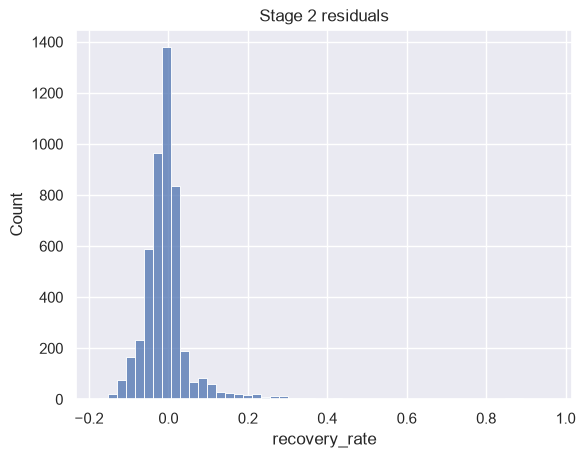

In [10]:
rr_pred_test = lgd_stage_2.predict(X2_test)
corr_stage_2 = np.corrcoef(y2_test, rr_pred_test)[0, 1]
print(f'Stage 2 correlation (actual vs predicted recovery rate): {corr_stage_2:.3f}')
print(f'Stage 2 MAE: {mean_absolute_error(y2_test, rr_pred_test):.3f}')
sns.histplot(y2_test - rr_pred_test, bins=50).set_title('Stage 2 residuals')

## Combine the two stages

In [11]:
# Recovery rate = (anything recovered? 0/1) × (expected share recovered), bounded to [0, 1].
rr_combined_test = np.clip(
    np.where(p_recovery_test > 0.5, 1, 0) * lgd_stage_2.predict(X_test), 0, 1)
y_rr_test = defaults.loc[X_test.index, 'recovery_rate']
print(f'Combined recovery-rate MAE on held-out defaults: {mean_absolute_error(y_rr_test, rr_combined_test):.3f}')
pd.Series(rr_combined_test).describe()

Combined recovery-rate MAE on held-out defaults: 0.061


count    8648.000000
mean        0.066927
std         0.053100
min         0.000000
25%         0.000000
50%         0.084599
75%         0.111649
max         0.262500
dtype: float64

## EAD: credit conversion factor (linear regression)

In [12]:
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X, defaults['CCF'], test_size=0.2, random_state=42)

ead_model = LinearRegression()
ead_model.fit(X3_train, y3_train)

summary_ead = pd.DataFrame({'Feature name': ['Intercept'] + list(X.columns),
                            'Coefficients': np.r_[ead_model.intercept_, ead_model.coef_],
                            'p_values': np.r_[np.nan, ead_model.p]})
summary_ead

,Feature name,Coefficients,p_values
0,Intercept,7.827821e-01,NaN
1,grade:A,-7.385536e-02,0.000000e+00
2,grade:B,-3.958804e-02,1.351808e-12
3,grade:C,-2.315967e-03,6.685657e-01
4,grade:D,2.561713e-02,5.900773e-06
5,grade:E,5.499130e-02,0.000000e+00
6,grade:F,7.719486e-02,0.000000e+00
7,home_ownership:MORTGAGE,-6.792476e-03,1.250753e-03
8,home_ownership:NONE,-5.138177e-04,9.936739e-01
9,home_ownership:OTHER,1.128839e-03,9.708619e-01


In [13]:
ccf_pred_test = np.clip(ead_model.predict(X3_test), 0, 1)
corr_ead = np.corrcoef(y3_test, ccf_pred_test)[0, 1]
print(f'EAD correlation (actual vs predicted CCF): {corr_ead:.3f}')
print(f'EAD MAE: {mean_absolute_error(y3_test, ccf_pred_test):.3f}')

EAD correlation (actual vs predicted CCF): 0.515
EAD MAE: 0.131


## Expected Loss for the whole portfolio

In [14]:
pd_model = joblib.load('../models/pd_model.sav')

X_all = lgd_ead_design_matrix(loan_data)
el = pd.DataFrame(index=loan_data.index)
el['funded_amnt'] = loan_data['funded_amnt']
el['grade'] = loan_data[[f'grade:{g}' for g in 'ABCDEFG']].astype(int).idxmax(axis=1).str[-1]

# PD = 1 - P(good) from the saved scorecard model.
el['PD'] = pd_model.model.predict_proba(pd_design_matrix(loan_data).to_numpy())[:, 0]

p_recovery = lgd_stage_1.model.predict_proba(X_all.to_numpy())[:, 1]
el['recovery_rate'] = np.clip(np.where(p_recovery > 0.5, 1, 0) * lgd_stage_2.predict(X_all), 0, 1)
el['LGD'] = 1 - el['recovery_rate']

el['CCF'] = np.clip(ead_model.predict(X_all), 0, 1)
el['EAD'] = el['CCF'] * el['funded_amnt']

el['EL'] = el['PD'] * el['LGD'] * el['EAD']
el[['PD', 'LGD', 'CCF', 'EAD', 'EL']].describe()

,PD,LGD,CCF,EAD,EL
count,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000
mean,0.109609,0.951410,0.734268,10765.265118,1104.187749
std,0.071618,0.055156,0.099702,6892.444731,1103.409539
min,0.006770,0.000000,0.313284,200.444865,0.000000
25%,0.055677,0.896041,0.670094,5473.711519,362.683168
50%,0.093635,1.000000,0.724847,9166.283659,729.083872
75%,0.147644,1.000000,0.799056,14619.395012,1447.479708
max,0.603665,1.000000,1.000000,35000.000000,11388.339298


In [15]:
total_el = el['EL'].sum()
total_funded = el['funded_amnt'].sum()
print(f'Portfolio funded amount: ${total_funded:,.0f}')
print(f'Expected loss:           ${total_el:,.0f}')
print(f'Expected loss rate:      {total_el / total_funded:.2%} of funded amount')

Portfolio funded amount: $6,664,052,450
Expected loss:           $514,866,185
Expected loss rate:      7.73% of funded amount


In [16]:
el_by_grade = el.groupby('grade').agg(
    loans=('EL', 'size'), mean_PD=('PD', 'mean'), mean_LGD=('LGD', 'mean'),
    mean_EAD=('EAD', 'mean'), total_EL=('EL', 'sum'), funded=('funded_amnt', 'sum'))
el_by_grade['EL_rate'] = el_by_grade['total_EL'] / el_by_grade['funded']
el_by_grade.style.format({'mean_PD': '{:.1%}', 'mean_LGD': '{:.1%}', 'mean_EAD': '${:,.0f}',
                          'total_EL': '${:,.0f}', 'funded': '${:,.0f}', 'EL_rate': '{:.2%}'})

,loans,mean_PD,mean_LGD,mean_EAD,total_EL,funded,EL_rate
grade,,,,,,,
A,74867,3.8%,96.7%,"$8,876","$21,261,640","$1,000,867,250",2.12%
B,136929,7.9%,95.9%,"$9,170","$86,153,027","$1,793,263,750",4.80%
C,125293,11.5%,95.2%,"$10,914","$137,289,272","$1,776,868,750",7.73%
D,76888,15.5%,94.1%,"$12,163","$123,700,802","$1,156,838,775",10.69%
E,35757,19.3%,93.0%,"$14,872","$89,096,131","$625,042,825",14.25%
F,13229,24.3%,89.9%,"$15,942","$44,271,605","$242,924,925",18.22%
G,3322,27.9%,91.5%,"$16,303","$13,093,708","$68,246,175",19.19%


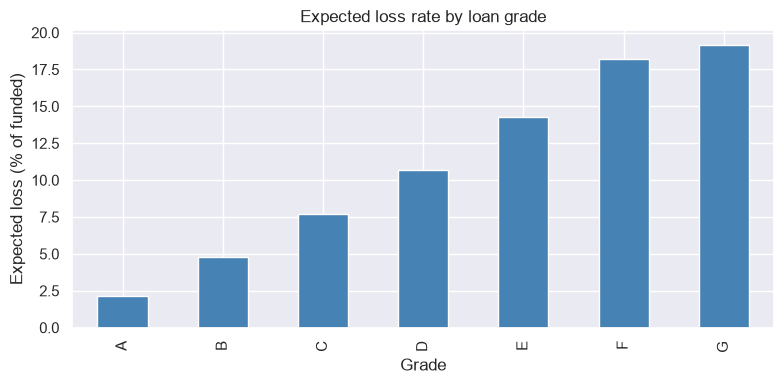

In [17]:
ax = (el_by_grade['EL_rate'] * 100).plot(kind='bar', figsize=(8, 4), color='steelblue')
ax.set_xlabel('Grade'); ax.set_ylabel('Expected loss (% of funded)')
ax.set_title('Expected loss rate by loan grade')
plt.tight_layout()

## Save the models

In [18]:
joblib.dump(lgd_stage_1, '../models/lgd_model_stage_1.sav')
joblib.dump(lgd_stage_2, '../models/lgd_model_stage_2.sav')
joblib.dump(ead_model, '../models/ead_model.sav')

['../models/ead_model.sav']